**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**02 | MATLAB Record Decoding and Trial Provenance**

![Stage 02 Essex participant and original trial provenance audit](../../images/02_workflow.svg)

**Objective:** Reconcile the original participant workbook with the 40 Essex MATLAB files, inspect every recorded movement element, evaluate trial-identifier readability and distinguish numeric measurements from unresolved MATLAB objects.

**Dataset:** Hollinger et al., *Scientific Data* (2026), [Figshare article 30225739, version 13](https://doi.org/10.6084/m9.figshare.30225739.v13). The full six-activity archive is different from the 444-record Walking/Running BoneNet derivative.

**Executed scope:** The pinned Figshare v13 archive and participant workbook were verified. The complete original source register contains 1,897 `Data` elements from 40 participants, and all 40 workbook IDs matched the corresponding MATLAB filenames. All 1,897 `UpdatedTrialID` values were readable, with no duplicates within their participant identifiers. Six stage-specific evidence files were saved.

**Scientific limitations:** The original FE principal strain targets are derived from modelling rather than direct in-vivo measurements; source publication describes FE points every tenth position of a normalised movement cycle. No assumption is made that opaque MATLAB data contain verified 101-point strain curves. No model training, subject-independent evaluation or clinical validation is performed.

**Recorded result:** IMU fields for 1,897 records and FE fields for 1,729 records remain structured or opaque; 168 FE fields are empty. The source-register Quality Gate **PASSED**. Numeric waveform recovery, verified strain units, temporal alignment, complete trial-to-signal validation and regression readiness remain **NOT ESTABLISHED**.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}


# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")


# ---------------------------- 2. Standard Library ----------------------------
import json
from pathlib import Path


# ----------------- 3. Scientific Computing and Data Analysis -----------------
import pandas as pd


# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))


# ------------------ 5. Shared and Study Research Utilities -------------------
from core.output_download import download_outputs_from_colab
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, fetch_version_manifest,
    find_published_file, ensure_source_file, inspect_matlab_archive,
    extract_matlab_files,
)
from essex_record_audit import (
    audit_workbook_ids, audit_mat_records, summarise_trial_evidence,
)


# ------------------- 6. Data and Research Output Locations -------------------
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
output_dir = root / "biomechanical_load_estimation" / "output"
raw_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)

print("Figshare article:", ARTICLE_ID, "| version:", ARTICLE_VERSION)
print("Research output directory:", output_dir)

Figshare article: 30225739 | version: 13
Research output directory: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Published Data and Reproducible Acquisition**

Google Colab may start with an empty runtime. To make Stage 02 independently executable, we use the official version-pinned Figshare API and the Stage 01 source-integrity helpers. Only `MATLAB.zip` and `SubCharacteristics.xlsx` are downloaded or reused; raw files remain in the git-ignored data directory.

The source archive is verified using its published byte size and any supplied MD5, plus a local SHA256. ZIP member paths, CRC values and the 40 MAT files are checked before extraction.

In [3]:
# =============== 02. Official Source and Participant Workbook ================

# -------------- 1. Verify Figshare Metadata and File Selection ---------------
article, source_files = fetch_version_manifest()
mat_item = find_published_file(source_files, "MATLAB.zip")
workbook_item = find_published_file(source_files, "SubCharacteristics.xlsx")
print("Source:", article.get("title"))


# ---------------- 2. Verify and Prepare Original Source Data -----------------
zip_path, zip_hashes = ensure_source_file(mat_item, raw_dir)
workbook_path, workbook_hashes = ensure_source_file(workbook_item, raw_dir)
inventory = inspect_matlab_archive(zip_path, expected_mat_files=40)
mat_paths = extract_matlab_files(zip_path, mat_dir, inventory)
assert len(mat_paths) == 40

print("MATLAB source files:", len(mat_paths))
print("ZIP SHA256:", zip_hashes["sha256"])
print("Participant workbook SHA256:", workbook_hashes["sha256"])

Source: Dataset for Rapid Estimation of Femoral Neck Loading During Gait and Dynamic Exercises
MATLAB source files: 40
ZIP SHA256: c50f10d1364686412b7ab64cac435dc85864dc8dbb34d2804b9cf37f2e29132d
Participant workbook SHA256: fe46eb6f5c6e892dfde88ce296e7ae3b0a5cdba194e03d29d618ddf527e2fb84


**03. Participant Identity Reconciliation**

The participant-ID validation issue identified during the first Stage 01 execution was corrected and rerun before this stage. Stage 02 provides an independent cross-check against the same pinned source rather than assuming that the previous result guarantees identifier consistency.

Stage 02 reads the published workbook with its original column spelling `Participent ID`, recognises actual `SubjXX` identifiers and excludes aggregate spreadsheet rows. In the recorded execution, all 40 participant IDs matched the 40 original MAT filenames, with no missing or duplicated IDs. No demographic or health-history information was exported.

In [4]:
# ============= 03. Source Workbook and Participant Identity Gate =============

# ----------------- 1. Parse Original Participant Identifiers -----------------
mat_ids = sorted(path.stem.lower() for path in mat_paths)
workbook_audit, verified_subjects = audit_workbook_ids(
    workbook_path, mat_ids
)
display(pd.DataFrame([{
    "recognised_rows": workbook_audit["recognised_participant_rows"],
    "unique_ids": workbook_audit["unique_participant_ids"],
    "duplicate_ids": workbook_audit["duplicate_ids"],
    "source_id_match": workbook_audit["id_alignment_passed"],
}]))
print("Missing workbook IDs:", workbook_audit["mat_ids_not_in_workbook"])
print("Unexpected workbook IDs:", workbook_audit["workbook_ids_not_in_mat"])


# ---------------- 2. Record and Require Valid Source Identity ----------------
verified_subjects.to_csv(
    output_dir / "02_workbook_subject_ids.csv", index=False
)
if not workbook_audit["id_alignment_passed"]:
    raise ValueError(
        "Published workbook and MAT participants disagree. "
        "Do not continue to model construction before resolving provenance."
    )
print("Participant identity gate: PASSED")

,recognised_rows,unique_ids,duplicate_ids,source_id_match
0,40,40,0,True


Missing workbook IDs: []
Unexpected workbook IDs: []
Participant identity gate: PASSED


**04. Original Movement Records and Trial Identity**

The source `Data` array contains repeated elements within participant files. We retain each source-file name and a zero-based record index as reproducible provenance, but **do not** assume this index is a native trial number.

The recorded execution recovered readable `UpdatedTrialID` values for all 1,897 source records, with no duplicates of the participant-plus-updated-trial combination. Source tasks were also readable for all records. This establishes the observed identifier register, **not** independently verified signal-target alignment or a final model-ready trial mapping; missing or opaque MATLAB fields are not inferred from data order.

In [5]:
# ============== 04. Original Record and Trial Provenance Audit ===============

# --------------------- 1. Inspect All Source MAT Records ---------------------
records = audit_mat_records(mat_paths)
trial_summary = summarise_trial_evidence(records)
display(records[[
    "subject_id", "local_record_index", "task", "subtask",
    "updated_trial_id", "imu_representation", "fe_representation"
]].head(18))

print("Audited source records:", trial_summary["source_records"])
print("Participants:", trial_summary["source_participants"])
print("Readable UpdatedTrialID fields:", trial_summary["readable_updated_trial_ids"])


# --------------------- 2. Save Original Record Registry ----------------------
records.to_csv(
    output_dir / "02_original_record_registry.csv", index=False
)
print("Duplicate participant/trial IDs:", trial_summary["duplicate_subject_trial_ids"])
print("No inferred source-trial identifiers were created.")

,subject_id,local_record_index,task,subtask,updated_trial_id,imu_representation,fe_representation
0,subj04,0,CounterJumps,100,CounterJumpsMax1,structured_or_opaque,structured_or_opaque
1,subj04,1,CounterJumps,100,CounterJumpsMax2,structured_or_opaque,structured_or_opaque
2,subj04,2,CounterJumps,100,CounterJumpsMax3,structured_or_opaque,structured_or_opaque
3,subj04,3,CounterJumps,50,CounterJumpsMin1,structured_or_opaque,structured_or_opaque
4,subj04,4,CounterJumps,50,CounterJumpsMin2,structured_or_opaque,structured_or_opaque
5,subj04,5,CounterJumps,50,CounterJumpsMin3,structured_or_opaque,structured_or_opaque
6,subj04,6,CounterJumps,75,CounterJumpsMed1,structured_or_opaque,structured_or_opaque
7,subj04,7,CounterJumps,75,CounterJumpsMed2,structured_or_opaque,structured_or_opaque
8,subj04,8,CounterJumps,75,CounterJumpsMed3,structured_or_opaque,structured_or_opaque
9,subj04,9,Running,Fast,RunningFast1,structured_or_opaque,structured_or_opaque


Audited source records: 1897
Participants: 40
Readable UpdatedTrialID fields: 1897
Duplicate participant/trial IDs: 0
No inferred source-trial identifiers were created.


**05. IMU and Femoral Neck Strain Representation**

The source can contain MATLAB objects representing tables and other structured values. This notebook reports the actual classes of original `IMU` and `e1e3` fields without treating opaque representations as numeric waveforms. The actual audit classified all 1,897 `IMU` fields as structured or opaque. Of the `e1e3` fields, 1,729 were structured or opaque and 168 were empty; none was verified as a finite numeric waveform. Target order, physical units and the FE temporal grid remain unverified.

Representation counts are not performance metrics. Each movement record is still associated with a participant, so individual time points cannot be treated as independent subjects.

In [6]:
# =============== 05. IMU and FE Representation Quality Profile ===============

# -------------- 1. Group Source Representations by Participant ---------------
coverage = (
    records.groupby(
        ["subject_id", "imu_representation", "fe_representation"]
    ).size().rename("records").reset_index()
)
coverage.to_csv(
    output_dir / "02_modality_representation.csv", index=False
)
display(coverage.head(18))


# ------------------- 2. Report Source Encoding Categories --------------------
encoding = pd.DataFrame(
    [{"modality": "IMU", "representation": k, "records": int(v)}
     for k, v in trial_summary["imu_encoding_counts"].items()]
    + [{"modality": "FE", "representation": k, "records": int(v)}
       for k, v in trial_summary["fe_encoding_counts"].items()]
)
display(encoding)
encoding.to_csv(
    output_dir / "02_modality_encoding_summary.csv", index=False
)
print("FE waveform units and temporal grid: NOT VERIFIED")

,subject_id,imu_representation,fe_representation,records
0,subj04,structured_or_opaque,structured_or_opaque,48
1,subj05,structured_or_opaque,structured_or_opaque,48
2,subj06,structured_or_opaque,empty,9
3,subj06,structured_or_opaque,structured_or_opaque,39
4,subj08,structured_or_opaque,empty,9
5,subj08,structured_or_opaque,structured_or_opaque,39
6,subj09,structured_or_opaque,structured_or_opaque,42
7,subj10,structured_or_opaque,structured_or_opaque,48
8,subj11,structured_or_opaque,empty,6
9,subj11,structured_or_opaque,structured_or_opaque,34


,modality,representation,records
0,IMU,structured_or_opaque,1897
1,FE,structured_or_opaque,1729
2,FE,empty,168


FE waveform units and temporal grid: NOT VERIFIED


**06. Participant Coverage and Target Representation Figure**

The executed figure displays the observed per-participant source-record counts and the FE field-representation categories: 1,729 structured/opaque and 168 empty. These are descriptive source-data findings, not reconstructed FE strain trajectories or measures of prediction accuracy.

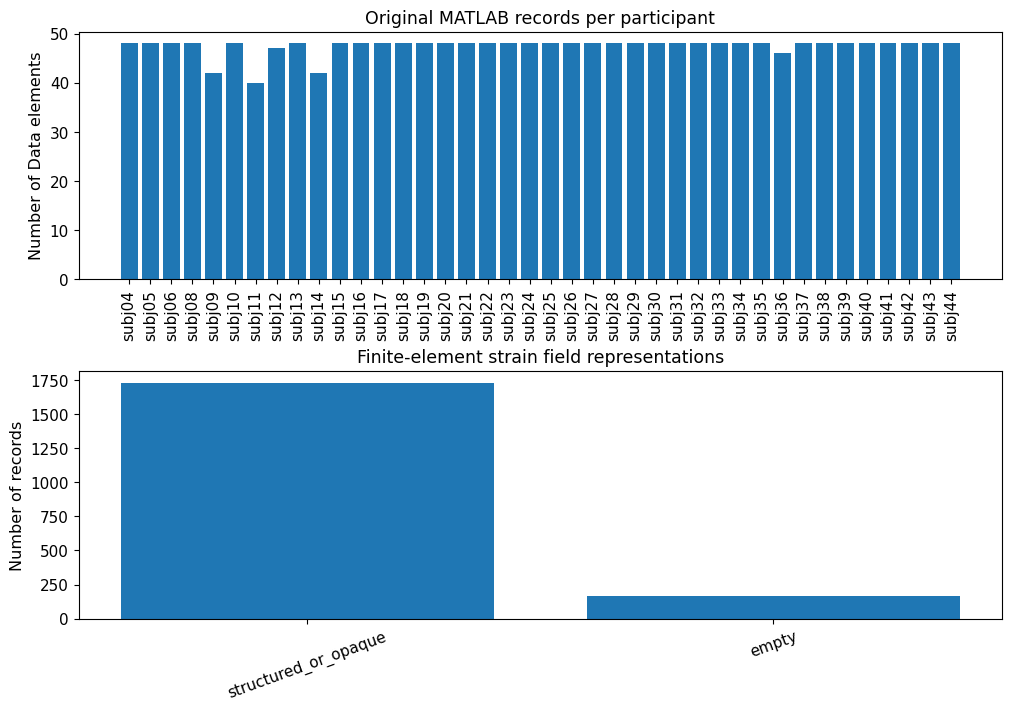

In [7]:
# ============== 06. Source Record Coverage and Encoding Figure ===============

# -------------------- 1. Visualise Observed Record Counts --------------------
participant_counts = records.groupby("subject_id").size().sort_index()
fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
axes[0].bar(participant_counts.index, participant_counts.values)
axes[0].set_title("Original MATLAB records per participant")
axes[0].set_ylabel("Number of Data elements")
axes[0].tick_params(axis="x", labelrotation=90)


# --------------- 2. Visualise Target Representation Categories ---------------
fe_counts = records["fe_representation"].value_counts()
axes[1].bar(fe_counts.index, fe_counts.values)
axes[1].set_title("Finite-element strain field representations")
axes[1].set_ylabel("Number of records")
axes[1].tick_params(axis="x", labelrotation=20)
save_figure(fig, output_dir / "02_trial_and_target_representation.png")
plt.show()

**07. Scientific Quality Gate and Dataset Readiness**

This stage explicitly separates **source-register validity** from **model readiness**. A valid register confirms the pinned version, participant match, unique local provenance keys and accounting for the original record population. It does **not** establish numeric FE extraction, validated trial identity, source units, correct temporal alignment or permissible participant-level regression.

The saved `02_record_provenance_and_quality_gate.json` records `source_registry_gate: PASSED` and `model_ready: false`. Although every `UpdatedTrialID` was readable, `verified_complete_trial_mapping` remains `false`: a readable identifier alone does not prove correct pairing of individual IMU observations and model-derived FE targets. These separate scientific boundaries must be preserved.

In [8]:
# ============= 07. Scientific Quality Gate and Provenance Record =============

# ----------- 1. Validate Source Participant and Record Accounting ------------
assert ARTICLE_ID == 30225739 and ARTICLE_VERSION == 13
assert workbook_audit["id_alignment_passed"]
assert trial_summary["source_participants"] == 40
assert trial_summary["source_records"] == 1897
assert records["local_record_key"].is_unique
assert set(records["subject_id"]) == set(mat_ids)
assert int(sum(trial_summary["fe_encoding_counts"].values())) == len(records)
assert int(sum(trial_summary["imu_encoding_counts"].values())) == len(records)


# ---------------- 2. Save Accurate Modelling-Readiness Flags -----------------
fe_numeric_count = trial_summary["fe_encoding_counts"].get(
    "numeric_candidate", 0
)
provenance = {
    "source_article_id": ARTICLE_ID,
    "version": ARTICLE_VERSION,
    "archive_sha256": zip_hashes["sha256"],
    "participant_workbook_sha256": workbook_hashes["sha256"],
    "participant_workbook_audit": workbook_audit,
    "source_record_summary": trial_summary,
    "source_registry_gate": "PASSED",
    "numeric_fe_candidates": int(fe_numeric_count),
    "verified_fe_target_order": False,
    "verified_fe_physical_units": False,
    "verified_imu_to_fe_temporal_alignment": False,
    "verified_complete_trial_mapping": False,
    "model_ready": False,
    "model_training_performed": False,
}
(output_dir / "02_record_provenance_and_quality_gate.json").write_text(
    json.dumps(provenance, indent=2) + "\n", encoding="utf-8"
)
print("STAGE 02 | SOURCE REGISTRY QUALITY GATE: PASSED")
print("MODEL-READY REGRESSION DATASET: NOT ESTABLISHED")
print("Model training and test evaluation performed: NO")

STAGE 02 | SOURCE REGISTRY QUALITY GATE: PASSED
MODEL-READY REGRESSION DATASET: NOT ESTABLISHED
Model training and test evaluation performed: NO


**08. Save and Retrieve Stage 02 Evidence**

The recorded execution checked and packaged six `02_*` artefacts, including the original record registry, source participant IDs, modality encoding tables, the provenance/Quality Gate JSON and the descriptive figure. Outputs are stored under `biomechanical_load_estimation/output/`. The Colab ZIP is not a GitHub push. Raw source files must remain outside Git.

In [ ]:
# ================= 08. Stage 02 Output Validation and Export =================

# ----------------- 1. Verify Expected Research Output Files ------------------
expected = [
    "02_workbook_subject_ids.csv",
    "02_original_record_registry.csv",
    "02_modality_representation.csv",
    "02_modality_encoding_summary.csv",
    "02_trial_and_target_representation.png",
    "02_record_provenance_and_quality_gate.json",
]
missing = [name for name in expected if not (output_dir / name).is_file()]
if missing:
    raise FileNotFoundError("Stage 02 output files missing: " + ", ".join(missing))
print("Stage 02 output files verified:", len(expected))


# ------------------ 2. Package Outputs for Colab Retrieval -------------------
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="02"
)


Stage 02 output files verified: 6
------------------------------------------------------------------------
Notebook stage: 02
Files packaged: 6
  + 02_modality_encoding_summary.csv
  + 02_modality_representation.csv
  + 02_original_record_registry.csv
  + 02_record_provenance_and_quality_gate.json
  + 02_trial_and_target_representation.png
  + 02_workbook_subject_ids.csv
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_02_Outputs.zip
GitHub Commit/Push performed: NO
